## IMPORTS

In [1]:
from datetime import datetime

import mlflow
from omegaconf import OmegaConf
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import Pipeline

import numpy as np


d:\conda_envs\def_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from src.data import (
    create_splits,
    fill_none,
    load_data,
    make_pipeline,
    make_test_split,
)



In [3]:
from src.boosting import (prepare_cat_columns, run_optuna_study, prepare_full_data, train_full_boosting, final_evaluation, save_boosting_model)

In [4]:
cfg = OmegaConf.load('config.yaml')

In [5]:
import warnings

warnings.filterwarnings('ignore')

## FULL REGRESSION RUN

In [6]:
# DATA PREPARATION
df = load_data(cfg)
df = fill_none(df)
df, test = make_test_split(cfg, df)
pipeline = make_pipeline(cfg, df)
df = create_splits(cfg, df) 
df, cat_features = prepare_cat_columns(df)

2026/11/19 21:00:15 INFO mlflow.tracking.fluent: Experiment with name 'optuna_study_lgbm_19112026_2100' does not exist. Creating a new experiment.
[I 2026-11-19 21:00:15,146] A new study created in memory with name: optuna_study_lgbm_19112026_2100
  0%|          | 0/5 [00:00<?, ?it/s]2026/11/19 21:00:15 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|lo

[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000908 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2932
[LightGBM] [Info] Number of data points in the train set: 934, number of used features: 73
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Start training from score 12.033135
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with posit

Best trial: 0. Best value: 0.126472:  20%|██        | 1/5 [00:02<00:10,  2.58s/it]

[I 2026-11-19 21:00:17,727] Trial 0 finished with value: 0.12647174190939411 and parameters: {'learning_rate': 0.03574712922600244, 'num_leaves': 61, 'max_depth': 8, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746, 'reg_alpha': 2.5348407664333426e-07, 'reg_lambda': 3.3323645788192616e-08}. Best is trial 0 with value: 0.12647174190939411.
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000836 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2932
[LightGBM] [Info] Number of data points in the train set: 934, number of used features: 73
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Start t

Best trial: 0. Best value: 0.126472:  40%|████      | 2/5 [00:04<00:06,  2.14s/it]

[I 2026-11-19 21:00:19,568] Trial 1 finished with value: 0.12937325912905623 and parameters: {'learning_rate': 0.19030368381735815, 'num_leaves': 44, 'max_depth': 8, 'subsample': 0.608233797718321, 'colsample_bytree': 0.9879639408647978, 'reg_alpha': 0.31044435499483225, 'reg_lambda': 8.148018307012941e-07}. Best is trial 0 with value: 0.12647174190939411.
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000714 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2932
[LightGBM] [Info] Number of data points in the train set: 934, number of used features: 73
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Start traini

... (2 outputs left out)

Best trial: 2. Best value: 0.124249:  80%|████████  | 4/5 [00:10<00:02,  2.71s/it]

[I 2026-11-19 21:00:25,444] Trial 3 finished with value: 0.12427201655684775 and parameters: {'learning_rate': 0.01607123851203988, 'num_leaves': 29, 'max_depth': 5, 'subsample': 0.7824279936868144, 'colsample_bytree': 0.9140703845572055, 'reg_alpha': 6.267062696005991e-07, 'reg_lambda': 0.00042472707398058225}. Best is trial 2 with value: 0.12424946760634493.
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000894 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2932
[LightGBM] [Info] Number of data points in the train set: 934, number of used features: 73
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Start tr

Best trial: 2. Best value: 0.124249: 100%|██████████| 5/5 [00:12<00:00,  2.57s/it]


[I 2026-11-19 21:00:27,976] Trial 4 finished with value: 0.13661033963121794 and parameters: {'learning_rate': 0.07500118950416987, 'num_leaves': 17, 'max_depth': 7, 'subsample': 0.6682096494749166, 'colsample_bytree': 0.6260206371941118, 'reg_alpha': 3.4671276804481113, 'reg_lambda': 4.905556676028774}. Best is trial 2 with value: 0.12424946760634493.


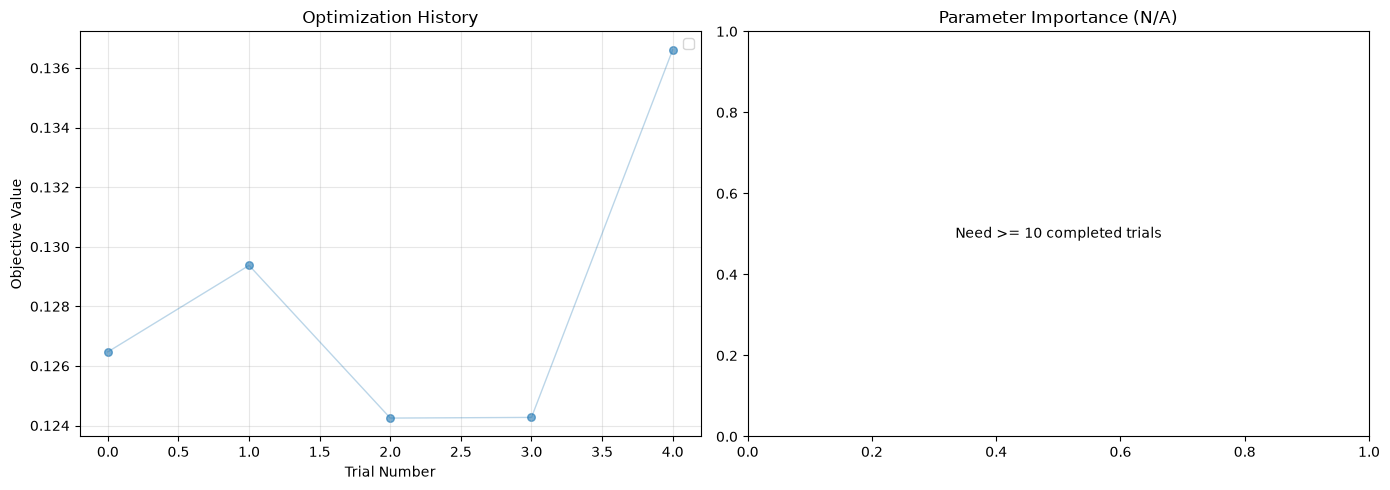


OPTUNA RESULTS
  Best trial:
  Value: 0.12425
  Params: {'learning_rate': 0.01855998084649059, 'num_leaves': 23, 'max_depth': 5, 'subsample': 0.8099025726528951, 'colsample_bytree': 0.7727780074568463, 'reg_alpha': 4.17890272377219e-06, 'reg_lambda': 0.0032112643094417484}
  Number: 2

Total trials: 5


In [7]:
experiment_name = f"optuna_study_{cfg.model_class}_{datetime.now().strftime('%d%m%Y_%H%M')}"
mlflow.set_experiment(experiment_name)

best_cfg, num_trees = run_optuna_study(cfg, df, pipeline, experiment_name, cat_features, show_plots=True)

In [8]:
# DATA PREPARATION
df = load_data(cfg)
df = fill_none(df)
df, test = make_test_split(cfg, df)
pipeline = make_pipeline(cfg, df)
df, cat_features = prepare_cat_columns(df)
test, cat_features = prepare_cat_columns(test)

X_train, y_train, X_test, y_test = prepare_full_data(cfg, df, pipeline, test)



In [9]:
with mlflow.start_run(run_name="final_model"):
    model = train_full_boosting(best_cfg, X_train, y_train, cat_features)
    # evaluation
    if X_test is not None:
        preds = model.predict(X_test)
        test_loss = final_evaluation(cfg, model, X_test, y_test)
    # save model
    save_boosting_model(cfg, model)
    

[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000744 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3149
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 75
[LightGBM] [Info] Start training from score 12.030658
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

In [14]:
def predict_by_task(model, X, cfg, threshold=0.5):
    """Unified inference. Returns (y_pred, y_proba).
    regression -> (values, None)
    binary     -> (labels, proba of class 1),  proba shape (n,)
    multiclass -> (labels, proba matrix),      proba shape (n, K)
    """
    task_type = cfg.task_type

    if task_type == 'regression':
        return np.asarray(model.predict(X)).ravel(), None

    proba = model.predict_proba(X)

    if task_type == 'binary':
        proba = proba[:, 1]
        y_pred = (proba >= threshold).astype(int)
    elif task_type == 'multiclass':
        y_pred = proba.argmax(axis=1)
    else:
        raise ValueError(f'Unknown task_type: {task_type}')

    return np.asarray(y_pred).ravel(), proba

In [17]:
y_pred, y_proba = predict_by_task(model, X_test, best_cfg)

[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1


In [19]:
print(y_proba)

None


## FULL BINARY RUN

In [6]:
# DATA PREPARATION
cfg = OmegaConf.load('binary_config.yaml')

df, y = load_breast_cancer(return_X_y=True, as_frame=True)
df['target'] = y

pipeline = Pipeline([
    ('skip', 'passthrough')])

df = create_splits(cfg, df) 
df, cat_features = prepare_cat_columns(df)



2026/11/17 17:22:43 INFO mlflow.tracking.fluent: Experiment with name 'optuna_study_lgbm_17112026_1722' does not exist. Creating a new experiment.
[I 2026-11-17 17:22:43,142] A new study created in memory with name: optuna_study_lgbm_17112026_1722
  0%|          | 0/5 [00:00<?, ?it/s]2026/11/17 17:22:43 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|lo

[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Number of positive: 286, number of negative: 169
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000232 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4536
[LightGBM] [Info] Number of data points in the train set: 455, number of used features: 30
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.628571 -> initscore=0.526093
[LightGBM] [Info] Start training from score 0.526093
[LightGBM] [Warning] No furthe

Best trial: 0. Best value: 0.0854545:  20%|██        | 1/5 [00:01<00:06,  1.73s/it]

[I 2026-11-17 17:22:44,868] Trial 0 finished with value: 0.08545447250529643 and parameters: {'learning_rate': 0.03574712922600244, 'num_leaves': 61, 'max_depth': 8, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746, 'reg_alpha': 2.5348407664333426e-07, 'reg_lambda': 3.3323645788192616e-08, 'is_unbalance': True}. Best is trial 0 with value: 0.08545447250529643.
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Number of positive: 286, number of negative: 169
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000131 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4536
[LightGBM] [Info] Number of data points in the train se

Best trial: 0. Best value: 0.0854545:  40%|████      | 2/5 [00:03<00:04,  1.52s/it]

[I 2026-11-17 17:22:46,240] Trial 1 finished with value: 0.0867208334766344 and parameters: {'learning_rate': 0.11114989443094977, 'num_leaves': 16, 'max_depth': 10, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'reg_alpha': 4.329370014459266e-07, 'reg_lambda': 4.4734294104626844e-07, 'is_unbalance': False}. Best is trial 0 with value: 0.08545447250529643.
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Number of positive: 286, number of negative: 169
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000156 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4536
[LightGBM] [Info] Number of data points in the train se

... (2 outputs left out)

Best trial: 2. Best value: 0.0788854:  80%|████████  | 4/5 [00:06<00:01,  1.57s/it]

[I 2026-11-17 17:22:49,456] Trial 3 finished with value: 0.08407790350679237 and parameters: {'learning_rate': 0.05748924681991978, 'num_leaves': 44, 'max_depth': 3, 'subsample': 0.8430179407605753, 'colsample_bytree': 0.6682096494749166, 'reg_alpha': 3.850031979199519e-08, 'reg_lambda': 3.4671276804481113, 'is_unbalance': True}. Best is trial 2 with value: 0.07888536232995201.
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Number of positive: 286, number of negative: 169
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000166 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4536
[LightGBM] [Info] Number of data points in the train set: 45

Best trial: 2. Best value: 0.0788854: 100%|██████████| 5/5 [00:08<00:00,  1.66s/it]


[I 2026-11-17 17:22:51,440] Trial 4 finished with value: 0.08238365380358283 and parameters: {'learning_rate': 0.028180680291847244, 'num_leaves': 19, 'max_depth': 8, 'subsample': 0.7760609974958406, 'colsample_bytree': 0.6488152939379115, 'reg_alpha': 0.00028614897264046574, 'reg_lambda': 2.039373116525212e-08, 'is_unbalance': True}. Best is trial 2 with value: 0.07888536232995201.


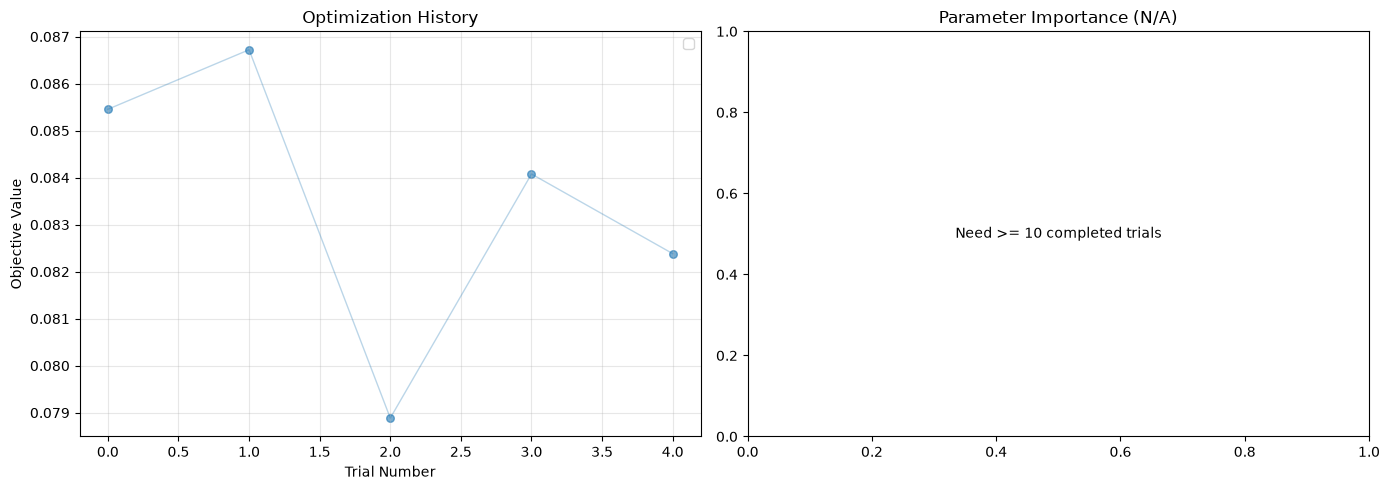


OPTUNA RESULTS
  Best trial:
  Value: 0.07889
  Params: {'learning_rate': 0.04345454109729477, 'num_leaves': 29, 'max_depth': 7, 'subsample': 0.6557975442608167, 'colsample_bytree': 0.7168578594140873, 'reg_alpha': 1.9826980964985924e-05, 'reg_lambda': 0.00012724181576752517, 'is_unbalance': True}
  Number: 2

Total trials: 5


In [7]:
experiment_name = f"optuna_study_{cfg.model_class}_{datetime.now().strftime('%d%m%Y_%H%M')}"
mlflow.set_experiment(experiment_name)

best_cfg, num_trees = run_optuna_study(cfg, df, pipeline, experiment_name, cat_features, show_plots=True)

In [8]:
### FULL TRAINING
df, y = load_breast_cancer(return_X_y=True, as_frame=True)
df['target'] = y

pipeline = Pipeline([
    ('skip', 'passthrough')])

df, cat_features = prepare_cat_columns(df)
df, test = make_test_split(cfg, df)
X_train, y_train, X_test, y_test = prepare_full_data(cfg, df, pipeline, test)


In [9]:
with mlflow.start_run(run_name="final_model"):
    model = train_full_boosting(best_cfg, X_train, y_train, cat_features, num_trees)
    # evaluation
    if X_test is not None:
        preds = model.predict(X_test)
        test_loss = final_evaluation(cfg, model, X_test, y_test)
    # save model
    save_boosting_model(cfg, model)

[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Number of positive: 286, number of negative: 169
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000171 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4548
[LightGBM] [Info] Number of data points in the train set: 455, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.628571 -> initscore=0.526093
[LightGBM] [Info] Start training from score 0.526093
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain

## MULTICLASS TEST RUN

In [14]:
from sklearn.datasets import load_iris

In [21]:
cfg = OmegaConf.load('multiclass_config.yaml')

df, y = load_iris(return_X_y=True, as_frame=True)
df['target'] = y

pipeline = Pipeline(steps=[('skip', 'passthrough')])

df = create_splits(cfg, df) 

2026/11/18 11:34:02 INFO mlflow.tracking.fluent: Experiment with name 'optuna_study_cat_18112026_1134' does not exist. Creating a new experiment.
[I 2026-11-18 11:34:03,004] A new study created in memory with name: optuna_study_cat_18112026_1134
Best trial: 0. Best value: 0.134862:  20%|██        | 1/5 [00:17<01:09, 17.39s/it]

[I 2026-11-18 11:34:20,383] Trial 0 finished with value: 0.13486151923049633 and parameters: {'learning_rate': 0.03574712922600244, 'depth': 10, 'l2_leaf_reg': 7.587945476302646, 'bagging_temperature': 0.5986584841970366, 'random_strength': 2.5361081166471375e-07}. Best is trial 0 with value: 0.13486151923049633.


Best trial: 0. Best value: 0.134862:  40%|████      | 2/5 [00:19<00:25,  8.45s/it]

[I 2026-11-18 11:34:22,590] Trial 1 finished with value: 0.13882165578525305 and parameters: {'learning_rate': 0.01699897838270077, 'depth': 4, 'l2_leaf_reg': 8.795585311974417, 'bagging_temperature': 0.6011150117432088, 'random_strength': 0.023585940584142682}. Best is trial 0 with value: 0.13486151923049633.


Best trial: 0. Best value: 0.134862:  60%|██████    | 3/5 [00:39<00:27, 13.51s/it]

[I 2026-11-18 11:34:42,126] Trial 2 finished with value: 0.1819876931240181 and parameters: {'learning_rate': 0.010725209743171996, 'depth': 10, 'l2_leaf_reg': 8.491983767203795, 'bagging_temperature': 0.21233911067827616, 'random_strength': 4.329370014459266e-07}. Best is trial 0 with value: 0.13486151923049633.


Best trial: 0. Best value: 0.134862:  80%|████████  | 4/5 [00:42<00:09,  9.49s/it]

[I 2026-11-18 11:34:45,447] Trial 3 finished with value: 0.13714461421918964 and parameters: {'learning_rate': 0.018659959624904916, 'depth': 6, 'l2_leaf_reg': 5.72280788469014, 'bagging_temperature': 0.43194501864211576, 'random_strength': 4.17890272377219e-06}. Best is trial 0 with value: 0.13486151923049633.


Best trial: 4. Best value: 0.13152: 100%|██████████| 5/5 [00:43<00:00,  8.78s/it] 


[I 2026-11-18 11:34:46,883] Trial 4 finished with value: 0.13152030824132985 and parameters: {'learning_rate': 0.08012737503998542, 'depth': 4, 'l2_leaf_reg': 3.629301836816963, 'bagging_temperature': 0.3663618432936917, 'random_strength': 0.00012724181576752517}. Best is trial 4 with value: 0.13152030824132985.


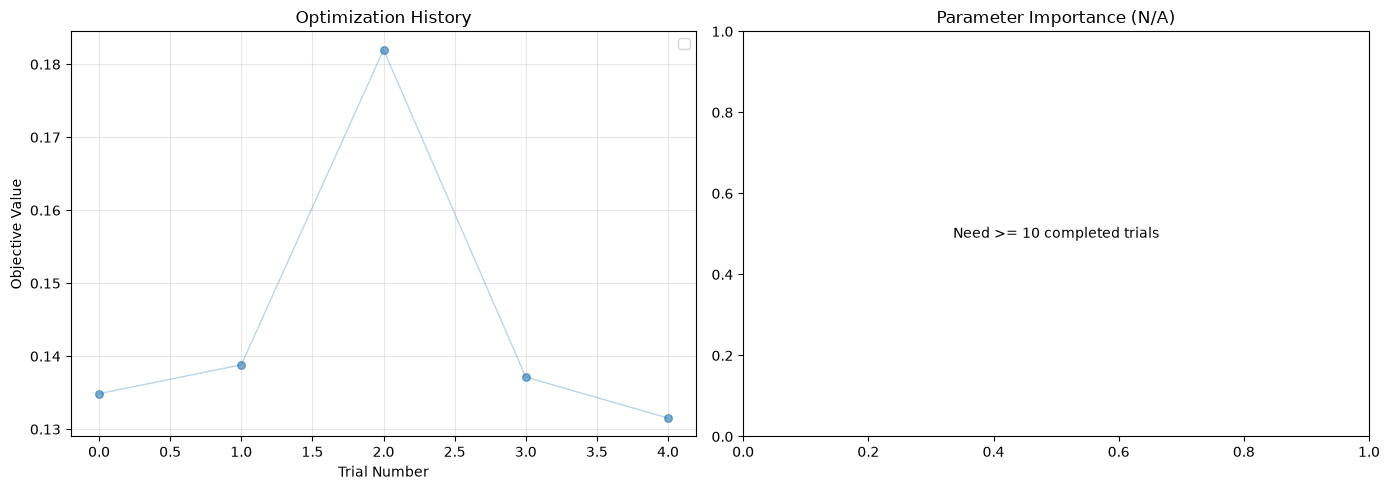


OPTUNA RESULTS
  Best trial:
  Value: 0.13152
  Params: {'learning_rate': 0.08012737503998542, 'depth': 4, 'l2_leaf_reg': 3.629301836816963, 'bagging_temperature': 0.3663618432936917, 'random_strength': 0.00012724181576752517}
  Number: 4

Total trials: 5


In [22]:
experiment_name = f"optuna_study_{cfg.model_class}_{datetime.now().strftime('%d%m%Y_%H%M')}"
mlflow.set_experiment(experiment_name)


best_cfg, num_trees = run_optuna_study(cfg, df, pipeline, experiment_name, show_plots=True)

In [23]:
df, y = load_iris(return_X_y=True, as_frame=True)
df['target'] = y

pipeline = Pipeline([
    ('skip', 'passthrough')])

df, cat_features = prepare_cat_columns(df)
df, test = make_test_split(cfg, df)
X_train, y_train, X_test, y_test = prepare_full_data(cfg, df, pipeline, test)

In [24]:
with mlflow.start_run(run_name="final_model"):
    model = train_full_boosting(best_cfg, X_train, y_train, cat_features, num_trees)
    # evaluation
    if X_test is not None:
        preds = model.predict(X_test)
        test_loss = final_evaluation(cfg, model, X_test, y_test)
    # save model
    save_boosting_model(cfg, model)

Test log_loss: 0.0321
Model saved and logged: model_cat.cbm
